# 09 · Robustez: ¿el MC4 no aporta, o el modelo estaba mal ajustado?

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 4 (comprobación de los modelos)

## A. Contexto de la etapa

**El resultado que ponemos a prueba.** Los Notebooks 04, 05 y 08 concluyeron que, comparando piezas del mismo producto, la herencia del MC4 casi no mejora la predicción del esfuerzo del Skinpass (ΔBending, ΔFuerza) ni de los defectos. Es la afirmación central de la tesis.

**La objeción de un revisor.** *"Usaron un solo algoritmo (LightGBM) con parámetros fijos. Quizá el MC4 sí aporta, pero el modelo no supo aprovecharlo: árboles muy pequeños para captar interacciones, demasiada regularización o un algoritmo inadecuado."*

**Cómo la respondemos.** Le damos al MC4 todas las oportunidades razonables de demostrar que aporta. Si después de eso sigue sin aportar, la conclusión queda mucho más sólida. Si aparece algo, lo reportamos.

## B. Fundamento conceptual

**1. Ajuste de hiperparámetros con validación anidada.** Los hiperparámetros (número de hojas, tasa de aprendizaje, número de árboles, regularización) controlan cuánta complejidad puede aprender el modelo. Si se eligen mirando el mismo pliegue con el que se evalúa, el resultado es optimista. La **validación anidada** lo evita:
- **Lazo externo:** 5 pliegues por campaña. Se evalúa en el pliegue que el modelo nunca vio.
- **Lazo interno:** dentro del entrenamiento de cada pliegue externo se separa un 20 % de campañas y se prueban varias configuraciones; se elige la mejor.
- Luego se reentrena con todo el entrenamiento del pliegue y se predice el pliegue externo.

Cada modelo (con y sin MC4) recibe **su propio ajuste**, para que la comparación sea justa.

**2. Otros algoritmos.**
- **Random Forest:** promedia muchos árboles profundos entrenados con muestras distintas. Captura interacciones de forma diferente al boosting.
- **Ridge:** regresión lineal con penalización. Si la relación fuera lineal y débil, un modelo lineal la encontraría mejor que un árbol.

Para estos dos, respuesta y predictores se centran por la media del producto **calculada en el entrenamiento de cada pliegue**.

**3. Aprendizaje del residuo (boosting a partir de un modelo base).** Primero se ajusta el mejor modelo **sin MC4** (M3: controles + Skinpass). Después se entrena otro modelo que parte de las predicciones de M3 (`init_score`) y solo puede corregirlas usando el MC4. Si el MC4 tuviera información que M3 no captó, este segundo modelo mejoraría la predicción fuera de muestra. Para que las predicciones de partida en entrenamiento sean honestas, se obtienen con una validación cruzada interna.

**4. Heterogeneidad.** Que el MC4 no aporte en promedio no excluye que aporte **en algunos productos**. Repetimos la comparación dentro de los productos con más piezas.

## C. Objetivo y metodología

| # | Prueba | Respuestas | Pregunta |
|---|---|---|---|
| 1 | LightGBM con hiperparámetros ajustados (anidado) | ΔBending, ΔFuerza | ¿Cambia el aporte del MC4 al ajustar bien cada modelo? |
| 2 | Random Forest y Ridge | ΔBending, ΔFuerza | ¿Depende el resultado del algoritmo? |
| 3 | Aprendizaje del residuo de M3 | ΔBending, ΔFuerza, B2 | ¿Tiene el MC4 información que el Skinpass no captó (incluidas interacciones)? |
| 4 | Por producto | ΔBending, ΔFuerza | ¿Aporta el MC4 en algún producto concreto? |

**Validación:** 5 pliegues por **campaña** (la estricta, Notebook 04), solo entrenamiento (enero-octubre). **Métrica:** R² dentro de producto fuera de muestra; para B2, PR-AUC.

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings, time
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import average_precision_score
from src.ternium import *

warnings.filterwarnings('ignore')
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 2025
rng = np.random.default_rng(SEMILLA)

In [3]:
B = cargar_base_analitica()
d = B[(B['pob_A'] == 1) & (~B['en_prueba'])].reset_index(drop=True)
for c in ['producto', 'usuario_skp']:
    d[c] = d[c].astype('category')

CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'es_reproceso', 'holgura_peso_pct']
MC4 = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
       'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado', 'error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango',
       'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c', 'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa',
       't_descarga_horno_c', 'tiempo_estancia_horno', 'cubierta_termica_pct', 'dias_mc4_skp']
SKP = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
       'riesgo_spring_back', 'usuario_skp']
MODELOS = {'M1 controles': ['producto'] + CONTROLES, 'M2 + MC4': ['producto'] + CONTROLES + MC4,
           'M3 + Skinpass': ['producto'] + CONTROLES + SKP, 'M4 completo': ['producto'] + CONTROLES + MC4 + SKP}
RESP = {'delta_bending': 'ΔBending', 'delta_fuerza': 'ΔFuerza'}

pliegue = np.zeros(len(d), int)
for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(d, groups=d['campana'])):
    pliegue[va] = k

def base_producto(y, tr, va):
    # Media del producto calculada solo con el entrenamiento del pliegue (referencia del R² dentro de producto).
    mp = pd.Series(y[tr]).groupby(d.loc[tr, 'producto'].values, observed=True).mean()
    return d.loc[va, 'producto'].map(mp).astype(float).fillna(y[tr].mean()).values

def r2_dentro(y, pred, base):
    return 100 * (1 - ((y - pred) ** 2).sum() / ((y - base) ** 2).sum())

BASE = {r: np.concatenate([base_producto(d[r].values, pliegue != k, pliegue == k) for k in range(5)]) for r in RESP}
ORDEN = np.concatenate([np.flatnonzero(pliegue == k) for k in range(5)])
BASE = {r: pd.Series(v, index=ORDEN).sort_index().values for r, v in BASE.items()}
print(f"Piezas: {len(d):,} · campañas: {d.campana.nunique()} · 5 pliegues por campaña")

Piezas: 43,175 · campañas: 581 · 5 pliegues por campaña


### 1. LightGBM con hiperparámetros ajustados (validación anidada)
Espacio de búsqueda: hojas por árbol, mínimo de piezas por hoja, tasa de aprendizaje, número de árboles, fracción de variables y de piezas, y regularización L2. Se sortean **10 configuraciones** (las mismas para todos los modelos) y en cada pliegue externo se elige la mejor con un 20 % de campañas del entrenamiento.

In [4]:
ESPACIO = dict(num_leaves=[7, 15, 31, 63, 127], min_child_samples=[20, 50, 100, 300], learning_rate=[0.02, 0.05, 0.1],
               n_estimators=[200, 400, 600], colsample_bytree=[0.5, 0.8, 1.0], subsample=[0.7, 1.0], reg_lambda=[0, 1, 10])
CONFIGS = [{k: v[rng.integers(len(v))] for k, v in ESPACIO.items()} for _ in range(10)]
CONFIGS[0] = dict(num_leaves=31, min_child_samples=100, learning_rate=0.05, n_estimators=400, colsample_bytree=0.8,
                  subsample=0.8, reg_lambda=1.0)          # la configuración por defecto del Notebook 04 entra en la búsqueda
fijos = dict(subsample_freq=1, random_state=SEMILLA, verbose=-1)

def anidado(resp, cols):
    y = d[resp].values; pred = np.full(len(d), np.nan); elegidas = []
    for k in range(5):
        tr, va = np.flatnonzero(pliegue != k), np.flatnonzero(pliegue == k)
        itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=k).split(tr, groups=d.loc[tr, 'campana']))
        itr, iva = tr[itr], tr[iva]
        errores = [((lgb.LGBMRegressor(**c, **fijos).fit(d.loc[itr, cols], y[itr]).predict(d.loc[iva, cols]) - y[iva]) ** 2).mean()
                   for c in CONFIGS]
        mejor = CONFIGS[int(np.argmin(errores))]; elegidas.append(mejor)
        pred[va] = lgb.LGBMRegressor(**mejor, **fijos).fit(d.loc[tr, cols], y[tr]).predict(d.loc[va, cols])
    return pred, elegidas

t0 = time.time()
filas, conf_elegidas, PRED_M3 = [], {}, {}
for r in RESP:
    for nombre, cols in MODELOS.items():
        p, el = anidado(r, cols)
        conf_elegidas[(r, nombre)] = el
        if nombre == 'M3 + Skinpass': PRED_M3[r] = p
        filas.append({'respuesta': RESP[r], 'modelo': nombre, 'R² dentro (ajustado)': r2_dentro(d[r].values, p, BASE[r])})
tab_aj = pd.DataFrame(filas)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")

# Comparación con los parámetros fijos del Notebook 04 (misma validación por campaña).
fijo04 = pd.read_csv(RESULTADOS / '04_validacion_por_campana.csv')
fijo04 = fijo04[fijo04.modelo.isin(MODELOS)].rename(columns={'pliegues por campaña': 'R² dentro (parámetros fijos, 04)'})
comp = tab_aj.merge(fijo04[['respuesta', 'modelo', 'R² dentro (parámetros fijos, 04)']], on=['respuesta', 'modelo'])
comp.round(2).to_csv(RESULTADOS / '09_ajuste_hiperparametros.csv', index=False)
comp.round(1)

Tiempo: 22.7 min


,respuesta,modelo,R² dentro (ajustado),"R² dentro (parámetros fijos, 04)"
0,ΔBending,M1 controles,1.8,-1.5
1,ΔBending,M2 + MC4,2.4,-0.2
2,ΔBending,M3 + Skinpass,13.0,11.5
3,ΔBending,M4 completo,14.0,12.2
4,ΔFuerza,M1 controles,28.2,27.0
5,ΔFuerza,M2 + MC4,30.2,27.5
6,ΔFuerza,M3 + Skinpass,24.4,24.5
7,ΔFuerza,M4 completo,30.7,29.5


In [5]:
def aportes(tabla, col):
    out = {}
    for r in tabla.respuesta.unique():
        t = tabla[tabla.respuesta == r].set_index('modelo')[col]
        out[r] = {'MC4 sobre controles (M2 − M1)': t['M2 + MC4'] - t['M1 controles'],
                  'MC4 propio (M4 − M3)': t['M4 completo'] - t['M3 + Skinpass'],
                  'Skinpass propio (M4 − M2)': t['M4 completo'] - t['M2 + MC4']}
    return pd.DataFrame(out).T

ap = pd.concat({'parámetros fijos (04)': aportes(comp, 'R² dentro (parámetros fijos, 04)'),
                'hiperparámetros ajustados': aportes(comp, 'R² dentro (ajustado)')}, axis=1)
print('Configuraciones elegidas para M4 (ΔBending), por pliegue:')
for c in conf_elegidas[('delta_bending', 'M4 completo')]:
    print('  ', {k: c[k] for k in ['num_leaves', 'min_child_samples', 'learning_rate', 'n_estimators']})
ap.round(1)

Configuraciones elegidas para M4 (ΔBending), por pliegue:
   {'num_leaves': 31, 'min_child_samples': 100, 'learning_rate': 0.02, 'n_estimators': 200}
   {'num_leaves': 15, 'min_child_samples': 50, 'learning_rate': 0.02, 'n_estimators': 600}
   {'num_leaves': 31, 'min_child_samples': 100, 'learning_rate': 0.02, 'n_estimators': 200}
   {'num_leaves': 31, 'min_child_samples': 100, 'learning_rate': 0.02, 'n_estimators': 200}
   {'num_leaves': 31, 'min_child_samples': 100, 'learning_rate': 0.02, 'n_estimators': 200}


parámetros fijos (04)                                                    hiperparámetros ajustados                                               
         MC4 sobre controles (M2 − M1) MC4 propio (M4 − M3) Skinpass propio (M4 − M2) MC4 sobre controles (M2 − M1) MC4 propio (M4 − M3) Skinpass propio (M4 − M2)
ΔBending                           1.3                  0.7                      12.5                           0.6                  0.9                      11.5
ΔFuerza                            0.6                  5.0                       2.0                           2.0                  6.2                       0.5

**Cómo leerlo.** Cada celda es cuántos puntos de R² dentro de producto agrega un bloque, fuera de muestra y validando por campaña, con los parámetros fijos del Notebook 04 y con los ajustados. Si el aporte del MC4 sigue cerca de 0 (o negativo) después del ajuste, la conclusión no dependía de los parámetros.

### 2. Otros algoritmos: Random Forest y Ridge
Trabajan sobre variables centradas por la media del producto (calculada en cada pliegue de entrenamiento), con faltantes imputados por la mediana del entrenamiento. El operador entra como variables indicadoras.

In [6]:
def matriz(cols, tr, va):
    num = [c for c in cols if c not in ('producto', 'usuario_skp')]
    X = d[num].astype(float).copy()
    X = X.fillna(X.iloc[tr].median())
    mp = X.iloc[tr].groupby(d.loc[tr, 'producto'].values, observed=True).mean()
    centro = mp.reindex(d['producto'].astype(str).values).fillna(X.iloc[tr].mean()).values
    X = X.values - centro
    if 'usuario_skp' in cols:
        X = np.c_[X, pd.get_dummies(d['usuario_skp'].astype(str)).values.astype(float)]
    return X[tr], X[va]

def otro_algoritmo(resp, cols, tipo):
    y = d[resp].values; pred = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = np.flatnonzero(pliegue != k), np.flatnonzero(pliegue == k)
        Xtr, Xva = matriz(cols, tr, va)
        base_tr = base_producto(y, tr, tr)
        if tipo == 'Ridge':
            mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
            m = Ridge(alpha=10.0).fit((Xtr - mu) / sd, y[tr] - base_tr); pred[va] = BASE[resp][va] + m.predict((Xva - mu) / sd)
        else:
            m = RandomForestRegressor(n_estimators=200, min_samples_leaf=50, max_features=0.5, n_jobs=-1, random_state=SEMILLA)
            m.fit(Xtr, y[tr] - base_tr); pred[va] = BASE[resp][va] + m.predict(Xva)
    return pred

t0 = time.time()
filas = []
for tipo in ['Ridge', 'Random Forest']:
    for r in RESP:
        for nombre, cols in MODELOS.items():
            filas.append({'algoritmo': tipo, 'respuesta': RESP[r], 'modelo': nombre,
                          'R² dentro': r2_dentro(d[r].values, otro_algoritmo(r, cols, tipo), BASE[r])})
tab_alg = pd.DataFrame(filas)
tab_alg.round(2).to_csv(RESULTADOS / '09_otros_algoritmos.csv', index=False)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")
ap_alg = pd.concat({a: aportes(tab_alg[tab_alg.algoritmo == a], 'R² dentro') for a in ['Ridge', 'Random Forest']}, axis=1)
ap_alg.round(1)

Tiempo: 2.4 min


Ridge                                                                Random Forest                                               
         MC4 sobre controles (M2 − M1) MC4 propio (M4 − M3) Skinpass propio (M4 − M2) MC4 sobre controles (M2 − M1) MC4 propio (M4 − M3) Skinpass propio (M4 − M2)
ΔBending                           0.3                  0.2                      10.9                           1.1                  1.5                      11.1
ΔFuerza                            3.9                  4.1                       0.1                           0.1                  0.5                      -0.4

### 3. Aprendizaje del residuo: ¿le queda algo al MC4 cuando el Skinpass ya habló?
Para cada pliegue externo:
1. Con una validación cruzada interna se obtienen predicciones **honestas** de M3 (controles + Skinpass) para las piezas de entrenamiento, y se ajusta M3 con todo el entrenamiento para predecir el pliegue externo.
2. Se entrena un segundo LightGBM que **parte de esas predicciones** (`init_score`) y solo puede corregirlas con: (a) solo el MC4, o (b) todas las variables, lo que le permite usar interacciones entre MC4 y Skinpass.
3. Se compara el error en el pliegue externo contra el de M3 solo.

Para **B2** (defecto de inspector, todos los modos), lo mismo con un clasificador: el punto de partida es el log-odds de M3 y la métrica es la PR-AUC.

In [7]:
P_BASE = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=SEMILLA, verbose=-1)
P_CORR = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=5.0, random_state=SEMILLA, verbose=-1)

def residuo(df, resp, folds, clasif=False):
    y = df[resp].values; cols3 = MODELOS['M3 + Skinpass']
    Modelo = lgb.LGBMClassifier if clasif else lgb.LGBMRegressor
    raw = lambda m, X: m.predict(X, raw_score=True) if clasif else m.predict(X)
    p3, pmc4, ptodo = (np.full(len(df), np.nan) for _ in range(3))
    for k in range(5):
        tr, va = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        init_tr = np.full(len(tr), np.nan)
        for j, (a, b) in enumerate(GroupKFold(n_splits=4).split(tr, groups=df.loc[tr, 'campana'])):
            init_tr[b] = raw(Modelo(**P_BASE).fit(df.loc[tr[a], cols3], y[tr[a]]), df.loc[tr[b], cols3])
        m3 = Modelo(**P_BASE).fit(df.loc[tr, cols3], y[tr]); init_va = raw(m3, df.loc[va, cols3])
        p3[va] = init_va
        for destino, cols in [(pmc4, ['producto'] + MC4), (ptodo, MODELOS['M4 completo'])]:
            mc = Modelo(**P_CORR).fit(df.loc[tr, cols], y[tr], init_score=init_tr)
            destino[va] = init_va + raw(mc, df.loc[va, cols])
    return p3, pmc4, ptodo

filas = []
for r in RESP:
    p3, pm, pt = residuo(d, r, pliegue)
    y = d[r].values
    filas.append({'resultado': RESP[r], 'métrica': 'R² dentro de producto (%)', 'M3': r2_dentro(y, p3, BASE[r]),
                  'M3 + corrección solo MC4': r2_dentro(y, pm, BASE[r]), 'M3 + corrección con todo': r2_dentro(y, pt, BASE[r])})
# B2 con todos los modos (como en el Notebook 05)
t = B[~B['en_prueba']].reset_index(drop=True)
for c in ['producto', 'usuario_skp']:
    t[c] = t[c].astype('category')
pl_t = np.zeros(len(t), int)
for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(t, groups=t['campana'])):
    pl_t[va] = k
p3, pm, pt = residuo(t, 'b2', pl_t, clasif=True)
sig = lambda z: 1 / (1 + np.exp(-z))
yb = t['b2'].values
filas.append({'resultado': 'B2 · inspector', 'métrica': 'PR-AUC / tasa base (×)',
              'M3': average_precision_score(yb, sig(p3)) / yb.mean(), 'M3 + corrección solo MC4': average_precision_score(yb, sig(pm)) / yb.mean(),
              'M3 + corrección con todo': average_precision_score(yb, sig(pt)) / yb.mean()})
tab_res = pd.DataFrame(filas)
tab_res.round(3).to_csv(RESULTADOS / '09_residuo.csv', index=False)
tab_res.round(2)

,resultado,métrica,M3,M3 + corrección solo MC4,M3 + corrección con todo
0,ΔBending,R² dentro de producto (%),11.51,10.07,8.96
1,ΔFuerza,R² dentro de producto (%),24.52,24.92,24.72
2,B2 · inspector,PR-AUC / tasa base (×),2.47,2.07,2.01


**Cómo leerlo.** La columna *M3* es el punto de partida sin MC4. *Corrección solo MC4* es lo que se logra cuando un segundo modelo intenta mejorar a M3 usando únicamente el MC4. *Corrección con todo* le permite combinar MC4 y Skinpass (interacciones). Si ninguna supera a M3 de forma apreciable, el MC4 no tiene información adicional que generalice a campañas nuevas.

### 4. ¿Aporta el MC4 dentro de algún producto?
Para los productos con más piezas (≥ 800), comparamos LightGBM con controles contra controles + MC4, con validación por campaña **dentro del producto**. Como cada producto tiene pocas piezas, el modelo es más pequeño.

In [8]:
P_PROD = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=50, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=SEMILLA, verbose=-1)
grandes = d['producto'].value_counts()
grandes = grandes[grandes >= 800].index
filas = []
for prod in grandes:
    s = d[d['producto'] == prod].reset_index(drop=True)
    if s['campana'].nunique() < 10: continue
    f = np.zeros(len(s), int)
    for k, (_, va) in enumerate(GroupKFold(n_splits=5).split(s, groups=s['campana'])):
        f[va] = k
    for r in RESP:
        y = s[r].values; preds = {}
        for nombre, cols in [('M1', CONTROLES), ('M2', CONTROLES + MC4)]:
            p = np.full(len(s), np.nan); base = np.full(len(s), np.nan)
            for k in range(5):
                tr, va = f != k, f == k
                p[va] = lgb.LGBMRegressor(**P_PROD).fit(s.loc[tr, cols], y[tr]).predict(s.loc[va, cols]); base[va] = y[tr].mean()
            preds[nombre] = 100 * (1 - ((y - p) ** 2).sum() / ((y - base) ** 2).sum())
        filas.append({'producto': prod, 'piezas': len(s), 'respuesta': RESP[r], 'M1': preds['M1'], 'M2 (+MC4)': preds['M2'],
                      'aporte MC4': preds['M2'] - preds['M1']})
tab_prod = pd.DataFrame(filas)
tab_prod.round(2).to_csv(RESULTADOS / '09_por_producto.csv', index=False)
print(f"Productos analizados: {tab_prod.producto.nunique()}")
tab_prod.groupby('respuesta')['aporte MC4'].describe(percentiles=[.1, .5, .9]).round(1)

Productos analizados: 4


,count,mean,std,min,10%,50%,90%,max
respuesta,,,,,,,,
ΔBending,4.0,-1.2,4.8,-7.8,-6.0,-0.1,2.7,3.2
ΔFuerza,4.0,7.9,10.6,-3.7,-2.1,9.0,17.1,17.3


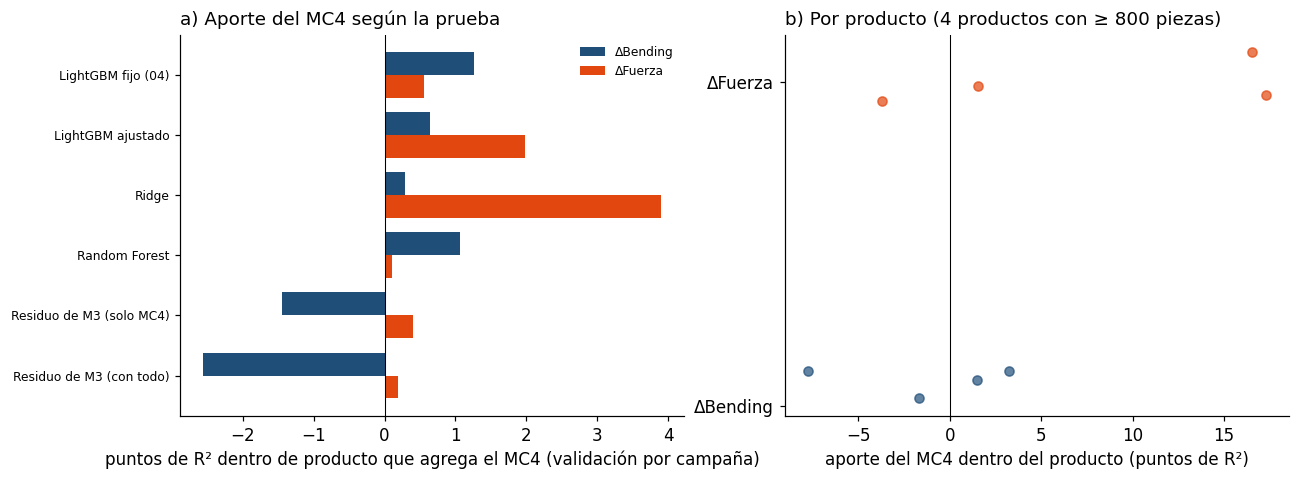

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# a) resumen del aporte del MC4 en todas las pruebas
res = []
for r in ['ΔBending', 'ΔFuerza']:
    res.append(('LightGBM fijo (04)', r, ap.loc[r, ('parámetros fijos (04)', 'MC4 sobre controles (M2 − M1)')]))
    res.append(('LightGBM ajustado', r, ap.loc[r, ('hiperparámetros ajustados', 'MC4 sobre controles (M2 − M1)')]))
    res.append(('Ridge', r, ap_alg.loc[r, ('Ridge', 'MC4 sobre controles (M2 − M1)')]))
    res.append(('Random Forest', r, ap_alg.loc[r, ('Random Forest', 'MC4 sobre controles (M2 − M1)')]))
    fila = tab_res[tab_res.resultado == r].iloc[0]
    res.append(('Residuo de M3 (solo MC4)', r, fila['M3 + corrección solo MC4'] - fila['M3']))
    res.append(('Residuo de M3 (con todo)', r, fila['M3 + corrección con todo'] - fila['M3']))
res = pd.DataFrame(res, columns=['prueba', 'respuesta', 'aporte'])
pruebas = res.prueba.unique(); y = np.arange(len(pruebas))
for k, (r, c) in enumerate([('ΔBending', COLORES['azul']), ('ΔFuerza', COLORES['naranja'])]):
    v = res[res.respuesta == r].set_index('prueba').loc[pruebas, 'aporte']
    ax[0].barh(y + (k - .5) * .38, v, .38, color=c, label=r)
ax[0].axvline(0, color='k', lw=.7); ax[0].set_yticks(y); ax[0].set_yticklabels(pruebas, fontsize=8); ax[0].invert_yaxis()
ax[0].set_xlabel('puntos de R² dentro de producto que agrega el MC4 (validación por campaña)'); ax[0].legend(fontsize=8)
ax[0].set_title('a) Aporte del MC4 según la prueba')
# b) por producto
for k, (r, c) in enumerate([('ΔBending', COLORES['azul']), ('ΔFuerza', COLORES['naranja'])]):
    v = tab_prod[tab_prod.respuesta == r]['aporte MC4']
    ax[1].scatter(v, np.full(len(v), k) + rng.uniform(-.15, .15, len(v)), color=c, alpha=.7)
ax[1].axvline(0, color='k', lw=.7); ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(['ΔBending', 'ΔFuerza'])
ax[1].set_xlabel('aporte del MC4 dentro del producto (puntos de R²)')
ax[1].set_title(f'b) Por producto ({tab_prod.producto.nunique()} productos con ≥ 800 piezas)')
guardar(fig, '09_robustez'); plt.show()

## E. Interpretación de los resultados

**1. Ajustar los hiperparámetros no cambia la conclusión para ΔBending.** Con validación anidada, cada modelo eligió su propia configuración. Para M4 se repitió casi siempre la misma: 31 hojas, al menos 100 piezas por hoja, tasa 0.02 y 200 árboles, más conservadora que la del Notebook 04. Los R² suben poco (M1 de −1.5 a 1.8; M4 de 12.2 a 14.0), pero los **aportes** apenas se mueven:
- **MC4 sobre controles:** 1.3 → 0.6 puntos.
- **MC4 propio:** 0.7 → 0.9 puntos.
- **Skinpass propio:** 12.5 → 11.5 puntos.

**2. Ningún algoritmo encuentra al MC4 en ΔBending.** El aporte del MC4 es de 0.2 a 0.3 puntos con Ridge (lineal) y de 1.1 a 1.5 con Random Forest. El Skinpass aporta ~11 puntos con los tres algoritmos. **El resultado no depende de LightGBM.**

**3. Al darle al MC4 el residuo de M3, no encuentra nada que generalice.**
- **ΔBending:** corregir a M3 con el MC4 **empeora** la predicción (11.5 → 10.1); con todas las variables, a 9.0. El MC4 tampoco aporta por interacción con el Skinpass.
- **ΔFuerza:** +0.4 puntos.
- **B2:** la mejora sobre el azar baja de 2.5× a 2.1×.

**4. ΔFuerza tiene un matiz.** El aporte del MC4 varía según el método:
- **MC4 sobre controles:** 0.1 (Random Forest) a 3.9 puntos (Ridge).
- **"MC4 propio" (M4 − M3):** 4 a 6 puntos con LightGBM y Ridge. Esta cifra está inflada: con validación por campaña, M3 predice ΔFuerza **peor** que los controles solos (24.4 contra 28.2), así que es un punto de partida debilitado.
- **La medida limpia** es el residuo de un M3 honesto: +0.4 puntos.

Que Ridge encuentre más que los árboles es compatible con un efecto **lineal y moderado**, como el de los días de espera (Notebook 06).

**5. Heterogeneidad: un grado donde el MC4 sí importa para la fuerza.** Solo 4 productos tienen al menos 800 piezas y 10 campañas.
- **ΔBending:** el MC4 no aporta en ninguno (−7.8 a +3.2 puntos).
- **ΔFuerza:** en los **dos productos de grado C071TM** (SAE J403 de 1.5-2.0 mm y TER de 2.5-3.0 mm), el MC4 agrega **~17 puntos** de R² dentro del producto. En los otros dos, nada.

Es una pista concreta: en ese grado la herencia del MC4 (incluida la espera) parece mover la fuerza que hace falta. Cuatro productos son pocos y se eligieron por volumen, no por hipótesis: se reporta como **hallazgo exploratorio**, no como resultado.

## F. Conclusiones de la etapa

### Respuesta a la objeción del revisor
> **El resultado central no dependía del modelo.** Con hiperparámetros ajustados por validación anidada, con Ridge, con Random Forest y con aprendizaje del residuo, la herencia del MC4 agrega como máximo ~1.5 puntos de R² a ΔBending dentro de producto y nada a los defectos. Para ΔFuerza agrega entre 0 y 4 puntos según el método, compatible con el efecto de los días de espera, con una excepción: el grado C071TM, donde agrega ~17 puntos.

### Hallazgos principales
1. Ajustar hiperparámetros sube los R² 1-3 puntos, pero no cambia los aportes por bloque.
2. Tres algoritmos distintos coinciden: el MC4 casi no aporta a ΔBending; el Skinpass aporta ~11 puntos.
3. El aprendizaje del residuo no encuentra información adicional del MC4, ni sola ni por interacción.
4. El "aporte propio del MC4" a ΔFuerza (M4 − M3) es engañoso cuando el modelo base está debilitado; la medida por residuo da +0.4.
5. **Exploratorio:** en el grado C071TM el MC4 explica ~17 puntos de ΔFuerza.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Afirmación central del artículo | Se mantiene; se reporta su robustez a algoritmo e hiperparámetros |
| Grado C071TM | Hallazgo exploratorio; candidato para estudiar el mecanismo de los días de espera (envejecimiento en aceros de bajo carbono) |
| Medida del aporte | Preferir el aprendizaje del residuo frente a la diferencia M4 − M3 cuando M3 sobreajusta |

### Limitaciones
- 10 configuraciones de búsqueda por modelo y una sola partición interna: es una búsqueda razonable, no exhaustiva.
- Solo 4 productos con volumen suficiente para el análisis por producto.